# 7. Stationary phase

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapter 6

Waves are described by integrals of oscillating exponentials: a diffracted field
is a sum over the points of an aperture, a dispersing wave packet a sum over
wavenumbers. In the limit of short wavelength or long time these integrals have the
form

$$ I(\lambda) = \int_a^b g(t)\,e^{i\lambda f(t)}\,\mathrm dt , \qquad \lambda \to \infty , $$

with a real phase $f$. The integrand does not become large anywhere; instead, it
oscillates faster and faster, and contributions from neighbouring points cancel.
Cancellation fails only where the phase is **stationary**, $f'(t_0) = 0$, and at the
endpoints. Kelvin's method of stationary phase evaluates the stationary points as
Laplace's method evaluates maxima, and integration by parts (Chapter 5) evaluates the
endpoints. The physical content is the ray picture of optics: the stationary points
are the geometric rays, the endpoints the edges that diffract.

In [1]:
import math

import matplotlib.pyplot as plt
import mpmath as mp
import numpy as np
from scipy.special import fresnel

try:
    import asymp as am
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import asymp as am

am.use_style()
mp.mp.dps = 30

## 7.1 The stationary-phase formula

Near a stationary point, $\lambda f(t) \approx \lambda f(t_0) + \tfrac12\lambda f''(t_0)(t - t_0)^2$.
The Fresnel integral $\int_{-\infty}^{\infty} e^{i\alpha s^2/2}\,\mathrm ds = \sqrt{2\pi/|\alpha|}\,e^{\pm i\pi/4}$,
with the sign of $\alpha$, then gives

$$ I(\lambda) \sim g(t_0)\,\sqrt{\frac{2\pi}{\lambda|f''(t_0)|}}\;
   e^{i\lambda f(t_0) \pm i\pi/4} , \qquad \pm = \operatorname{sign} f''(t_0) . $$

The formula looks like Laplace's, with an extra phase $\pm\pi/4$, but its accuracy
is different. An endpoint where the phase is not stationary contributes, by one
integration by parts,

$$ \frac{g(b)\,e^{i\lambda f(b)}}{i\lambda f'(b)} - \frac{g(a)\,e^{i\lambda f(a)}}{i\lambda f'(a)} , $$

which is of order $1/\lambda$. In Laplace's method endpoint contributions are
exponentially small compared with the maximum, because the integrand is
exponentially smaller there. In stationary phase the integrand has the same size
everywhere, and endpoints are smaller only by $\lambda^{-1/2}$. They must be kept
whenever more than the leading term is wanted.

## 7.2 Bessel functions

Bessel's integral

$$ J_0(x) = \frac1\pi\int_0^\pi e^{ix\cos\theta}\,\mathrm d\theta $$

has stationary points at the endpoints $\theta = 0$ ($f'' = -1$) and $\theta = \pi$
($f'' = +1$). Each lies at an end of the range, so each contributes half of the full
formula:

$$ J_0(x) \sim \frac{1}{2\pi}\sqrt{\frac{2\pi}{x}}\left(e^{i(x - \pi/4)} + e^{-i(x - \pi/4)}\right)
   = \sqrt{\frac{2}{\pi x}}\,\cos\!\left(x - \frac\pi4\right) . $$

The two contributions are the incoming and outgoing cylindrical waves. Each of them,
separately, is the large-$x$ form of a Hankel function,
$H_0^{(1)}(x) = J_0 + iY_0 \sim \sqrt{2/\pi x}\;e^{i(x - \pi/4)}\left(1 - \frac{i}{8x} - \frac{9}{128x^2} + \dots\right)$.
Checking the Hankel function rather than $J_0$ avoids a practical
difficulty: the error of the $J_0$ formula oscillates and passes through zero,
whereas the relative error of the complex $H_0^{(1)}$ is smooth, and its slope can be
measured.

In [2]:
xs = np.logspace(0.5, 3, 25)
H_exact = np.array([complex(mp.hankel1(0, x)) for x in xs])
lead = np.sqrt(2 / (np.pi * xs)) * np.exp(1j * (xs - np.pi / 4))
hank_err = {1: np.abs(lead / H_exact - 1),
            2: np.abs(lead * (1 - 1j / (8 * xs)) / H_exact - 1),
            3: np.abs(lead * (1 - 1j / (8 * xs) - 9 / (128 * xs**2)) / H_exact - 1)}
for N in (1, 2, 3):
    s, p = am.loglog_slope(xs, hank_err[N], fit_range=(100, 1000))
    print(f"H0(1), {N} term(s): relative error ~ {p:.4g} x^{s:.3f}")
xx = np.linspace(1, 30, 300)
j0_err = np.abs(np.sqrt(2 / (np.pi * xx)) * np.cos(xx - np.pi / 4) - am.mp_map(lambda x: mp.besselj(0, x), xx))
print(f"J0: largest error of the stationary-phase formula for 10 < x < 30: {j0_err[xx > 10].max():.4f}"
      f"  (amplitude sqrt(2/pi x) at x = 10: {np.sqrt(2 / (np.pi * 10)):.3f})")

H0(1), 1 term(s): relative error ~ 0.125 x^-1.000
H0(1), 2 term(s): relative error ~ 0.0703 x^-2.000
H0(1), 3 term(s): relative error ~ 0.07327 x^-3.000
J0: largest error of the stationary-phase formula for 10 < x < 30: 0.0025  (amplitude sqrt(2/pi x) at x = 10: 0.252)


The relative error of the leading term is $1/(8x)$, and each further term gains a
factor $1/x$; the error of three terms has the coefficient $225/3072$ of the fourth.
Beyond $x = 10$ the leading formula is within 0.003 of $J_0$, whose amplitude there
is 0.25: stationary phase is accurate after a couple of oscillations.

## 7.3 Diffraction at a straight edge

A plane wave falls on an opaque half-plane. In the Fresnel approximation the field at
a point of the observation screen is proportional to an integral over the open part
of the aperture,

$$ F(w) = \int_{-\infty}^{w} e^{i\pi t^2/2}\,\mathrm dt , $$

where $w$ measures the distance of the observation point from the geometric shadow
boundary, positive in the lit region, in units of the Fresnel length
$\sqrt{\lambda_\text{light} z/2}$. The intensity, normalised to 1 far from the edge,
is $I = |F|^2/2$. Here the large parameter is $|w|$, and the integral has one
stationary point, $t = 0$, and one endpoint, $t = w$.

* **Lit region** ($w > 0$): the stationary point lies inside the range and gives the
  full Gaussian, $\int_{-\infty}^{\infty} e^{i\pi t^2/2}\,\mathrm dt = 1 + i$: the
  undisturbed wave, the geometric ray. The endpoint contributes, by integration by
  parts, $-\int_w^\infty e^{i\pi t^2/2}\,\mathrm dt \sim -e^{i\pi w^2/2}\left(\frac{i}{\pi w} + \frac{1}{\pi^2 w^3} + \dots\right)$:
  a wave diffracted by the edge.
* **Shadow** ($w < 0$): the stationary point lies outside the range. Only the edge
  wave remains, and the intensity falls as $1/(2\pi^2 w^2)$.

The interference of the geometric wave with the edge wave produces the familiar
fringes on the lit side, whose contrast decreases as $1/w$.

In [3]:
def F_exact(w):
    S, C = fresnel(w)
    return (0.5 + C) + 1j * (0.5 + S)


def edge_wave(w, n_terms):
    """Endpoint contribution: -int_w^inf exp(i pi t^2/2) dt (w > 0), from integration by parts."""
    a = np.pi / 2
    terms = [1j / (2 * a * w), 1 / (4 * a**2 * w**3)]
    return -np.exp(1j * a * w**2) * sum(terms[:n_terms])


def F_asymptotic(w, n_terms=2):
    w = np.asarray(w, dtype=float)
    lit = (1 + 1j) + edge_wave(np.abs(w), n_terms)
    # in the shadow, F(w) = int_{|w|}^inf e^{i pi t^2/2} dt = -(edge wave at |w|)
    shadow = -edge_wave(np.abs(w), n_terms)
    return np.where(w > 0, lit, shadow)


ws = np.logspace(0, 2, 25)
fr_err = {N: np.abs(F_asymptotic(ws, N) - F_exact(ws)) for N in (1, 2)}
for N in (1, 2):
    s, p = am.loglog_slope(ws, fr_err[N], fit_range=(10, 100))
    print(f"edge diffraction, {N}-term edge wave: error of F ~ {p:.3g} |w|^{s:.3f}")
for w in (-3.0, -1.0, 1.0, 3.0):
    print(f"w = {w:+.0f}: intensity exact {abs(F_exact(w))**2 / 2:.4f}, asymptotic {abs(F_asymptotic(w))**2 / 2:.4f}")

edge diffraction, 1-term edge wave: error of F ~ 0.101 |w|^-3.000
edge diffraction, 2-term edge wave: error of F ~ 0.0967 |w|^-5.000
w = -3: intensity exact 0.0056, asymptotic 0.0056
w = -1: intensity exact 0.0411, asymptotic 0.0558
w = +1: intensity exact 1.2592, asymptotic 1.2728
w = +3: intensity exact 1.1076, asymptotic 1.1080


The error of the field falls as $|w|^{-3}$ with one term of the edge wave and as
$|w|^{-5}$ with two, as integration by parts predicts. One Fresnel length into the
lit region the asymptotic intensity is within about 1 % of the exact one. One
Fresnel length into the shadow it is 36 % too high, because there only the small
edge wave remains and its expansion is still poor; by $w = -3$ the error is below
1 %.
At the boundary itself, $w = 0$, the stationary point and the endpoint coincide, and
neither formula applies; the field there is given exactly by the Fresnel integrals,
a uniform description that the separate contributions cannot provide. Such
coalescences of special points are a recurring theme: Chapter 8 meets them again at
the turning point of the Airy function.

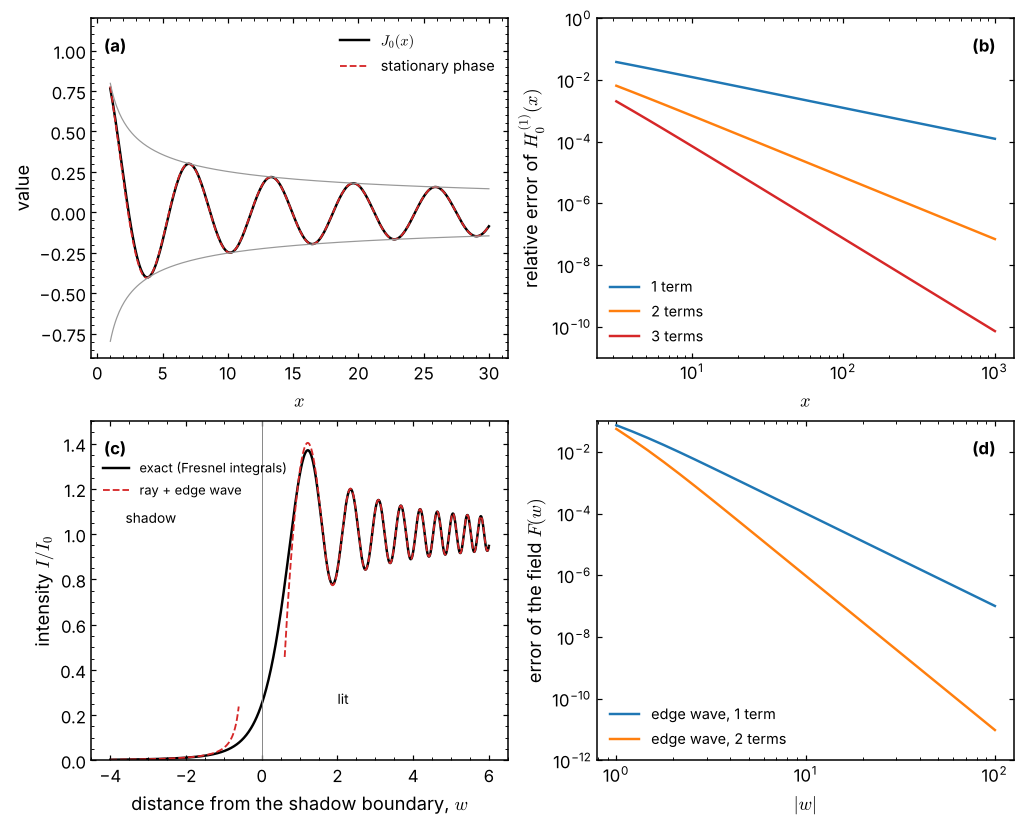

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.4))

ax = axes[0, 0]
ax.plot(xx, am.mp_map(lambda x: mp.besselj(0, x), xx), "k", lw=1.6, label=r"$J_0(x)$")
ax.plot(xx, np.sqrt(2 / (np.pi * xx)) * np.cos(xx - np.pi / 4), "C3--", lw=1.2, label="stationary phase")
ax.plot(xx, np.sqrt(2 / (np.pi * xx)), "0.6", lw=0.8)
ax.plot(xx, -np.sqrt(2 / (np.pi * xx)), "0.6", lw=0.8)
ax.set_xlabel("$x$"); ax.set_ylabel("value")
ax.set_ylim(-0.9, 1.2); ax.legend(loc="upper right"); am.panel_label(ax, "(a)")

ax = axes[0, 1]
for N, c in zip((1, 2, 3), ("C0", "C1", "C3")):
    ax.loglog(xs, hank_err[N], color=c, label=f"{N} term" + ("s" if N > 1 else ""))
ax.set_xlabel("$x$"); ax.set_ylabel(r"relative error of $H_0^{(1)}(x)$")
ax.set_ylim(1e-11, 1); ax.legend(loc="lower left"); am.panel_label(ax, "(b)", x=0.9)

ax = axes[1, 0]
wg = np.linspace(-4, 6, 800)
ax.plot(wg, np.abs(F_exact(wg))**2 / 2, "k", lw=1.6, label="exact (Fresnel integrals)")
m = np.abs(wg) > 0.6
ax.plot(wg[m & (wg > 0)], np.abs(F_asymptotic(wg[m & (wg > 0)]))**2 / 2, "C3--", lw=1.2, label="ray + edge wave")
ax.plot(wg[m & (wg < 0)], np.abs(F_asymptotic(wg[m & (wg < 0)]))**2 / 2, "C3--", lw=1.2)
ax.axvline(0, color="0.5", lw=0.6)
ax.text(-3.6, 1.05, "shadow", fontsize=9); ax.text(2.0, 0.25, "lit", fontsize=9)
ax.set_xlabel("distance from the shadow boundary, $w$"); ax.set_ylabel("intensity $I/I_0$")
ax.set_ylim(0, 1.5); ax.legend(loc="upper left", bbox_to_anchor=(0.0, 0.92), fontsize=8.5); am.panel_label(ax, "(c)")

ax = axes[1, 1]
for N, c in zip((1, 2), ("C0", "C1")):
    ax.loglog(ws, fr_err[N], color=c, label=f"edge wave, {N} term" + ("s" if N > 1 else ""))
ax.set_xlabel("$|w|$"); ax.set_ylabel("error of the field $F(w)$")
ax.set_ylim(1e-12, 1e-1); ax.legend(loc="lower left"); am.panel_label(ax, "(d)", x=0.9)
plt.show()

**(a)** $J_0(x)$ and its stationary-phase approximation; grey: the envelope
$\pm\sqrt{2/\pi x}$. **(b)** Relative error of the expansion of the Hankel function
with one to three terms. **(c)** Intensity behind a straight edge: exact, and the sum
of the geometric wave and the edge wave (not drawn within 0.6 of the boundary).
**(d)** Error of the asymptotic field with one and two terms of the edge wave.

## Summary

* For oscillatory integrals, the leading contributions come from points of
  stationary phase, each giving $g\sqrt{2\pi/\lambda|f''|}\,e^{i\lambda f \pm i\pi/4}$.
* Endpoints contribute at relative order $\lambda^{-1/2}$, not exponentially less as
  in Laplace's method; they are found by integration by parts.
* Stationary points are rays, endpoints are edges: the asymptotics of the integral
  is geometrical optics plus edge diffraction.
* When a stationary point and an endpoint (or two stationary points) coincide, the
  separate formulas fail and a uniform description is needed.
* Errors of oscillating approximations are best checked on a complex combination
  whose error does not oscillate.

## Suggested references

* C. M. Bender and S. A. Orszag, *Advanced Mathematical Methods for Scientists
  and Engineers* (McGraw-Hill, 1978; Springer, 1999).
* N. Bleistein and R. A. Handelsman, *Asymptotic Expansions of Integrals* (Holt,
  Rinehart and Winston, 1975; Dover, 1986).
* M. Born and E. Wolf, *Principles of Optics*, 7th ed. (Cambridge University
  Press, 1999).
* F. W. J. Olver, *Asymptotics and Special Functions* (Academic Press, 1974;
  A K Peters, 1997).

## Exercises

1. A wave packet $u(x, t) = \int A(k)\,e^{i(kx - k^2t)}\,\mathrm dk$ disperses. Show
   by stationary phase that for large $t$, $u \approx A(x/2t)\sqrt{\pi/t}\,e^{ix^2/4t - i\pi/4}$,
   and check it for a Gaussian $A(k)$, for which $u$ is known exactly.
2. Find the large-$x$ behaviour of $J_n(x) = \frac1\pi\int_0^\pi\cos(n\theta - x\sin\theta)\,\mathrm d\theta$.
3. Show that the fringe maxima on the lit side of the edge lie near
   $w^2 = 4m + \tfrac32$, $m = 0, 1, 2, \dots$, and compare with the exact pattern.
4. What goes wrong with the stationary-phase formula for $\int e^{i\lambda t^3}\,\mathrm dt$?
   Find the correct leading behaviour.

---

**Previous:** [6. Laplace's method](06_laplaces_method.ipynb) &nbsp;·&nbsp; **Next:** [8. Steepest descent and saddle points](08_steepest_descent.ipynb)